<a href="https://colab.research.google.com/github/UcciBr/Processual-1---Minera-o-de-Dados/blob/main/combust_veis_primeiro_semestre_2026.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
df_limpo = df.drop(columns=['Valor de Compra', 'Complemento'], errors='ignore')

df_limpo['Valor de Venda'] = df_limpo['Valor de Venda'].str.replace(',', '.').astype(float)

df_limpo.dropna(inplace=True)

print(f"Quantidade de registros após a limpeza: {len(df_limpo)}")
display(df_limpo.head(3))

Quantidade de registros após a limpeza: 421684


,Regiao - Sigla,Estado - Sigla,Municipio,Revenda,CNPJ da Revenda,Nome da Rua,Numero Rua,Bairro,Cep,Produto,Data da Coleta,Valor de Venda,Unidade de Medida,Bandeira
0,N,AC,CRUZEIRO DO SUL,AMAZONIA COMERCIO DE DERIVADOS DE PETROLEO LTDA,01.492.748/0003-83,AVENIDA COPACABANA,440,COPACABANA,69980-000,GASOLINA,02/01/2026,7.97,R$ / litro,IPIRANGA
1,N,AC,CRUZEIRO DO SUL,AMAZONIA COMERCIO DE DERIVADOS DE PETROLEO LTDA,01.492.748/0003-83,AVENIDA COPACABANA,440,COPACABANA,69980-000,DIESEL,02/01/2026,8.15,R$ / litro,IPIRANGA
2,N,AC,CRUZEIRO DO SUL,AMAZONIA COMERCIO DE DERIVADOS DE PETROLEO LTDA,01.492.748/0003-83,AVENIDA COPACABANA,440,COPACABANA,69980-000,DIESEL S10,02/01/2026,8.17,R$ / litro,IPIRANGA


In [ ]:
df_limpo.info()

<class 'pandas.core.frame.DataFrame'>
Index: 421684 entries, 0 to 422417
Data columns (total 14 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   Regiao - Sigla     421684 non-null  object 
 1   Estado - Sigla     421684 non-null  object 
 2   Municipio          421684 non-null  object 
 3   Revenda            421684 non-null  object 
 4   CNPJ da Revenda    421684 non-null  object 
 5   Nome da Rua        421684 non-null  object 
 6   Numero Rua         421684 non-null  object 
 7   Bairro             421684 non-null  object 
 8   Cep                421684 non-null  object 
 9   Produto            421684 non-null  object 
 10  Data da Coleta     421684 non-null  object 
 11  Valor de Venda     421684 non-null  float64
 12  Unidade de Medida  421684 non-null  object 
 13  Bandeira           421684 non-null  object 
dtypes: float64(1), object(13)
memory usage: 48.3+ MB


In [ ]:
linhas, colunas = df_limpo.shape
print(f"O conjunto de dados possui {linhas} amostras (linhas) e {colunas} variáveis (colunas).\n")

media = df_limpo['Valor de Venda'].mean()
mediana = df_limpo['Valor de Venda'].median()
moda = df_limpo['Valor de Venda'].mode()[0]

print("--- Medidas de Tendência Central para o Valor de Venda ---")
print(f"Média:   R$ {media:.2f}")
print(f"Mediana: R$ {mediana:.2f}")
print(f"Moda:    R$ {moda:.2f}\n")

display(df_limpo['Valor de Venda'].describe())

O conjunto de dados possui 421684 amostras (linhas) e 14 variáveis (colunas).

--- Medidas de Tendência Central para o Valor de Venda ---
Média:   R$ 6.23
Mediana: R$ 6.49
Moda:    R$ 6.99



,Valor de Venda
count,421684.000000
mean,6.231631
std,1.028991
min,2.890000
25%,5.760000
50%,6.490000
75%,6.940000
max,9.990000


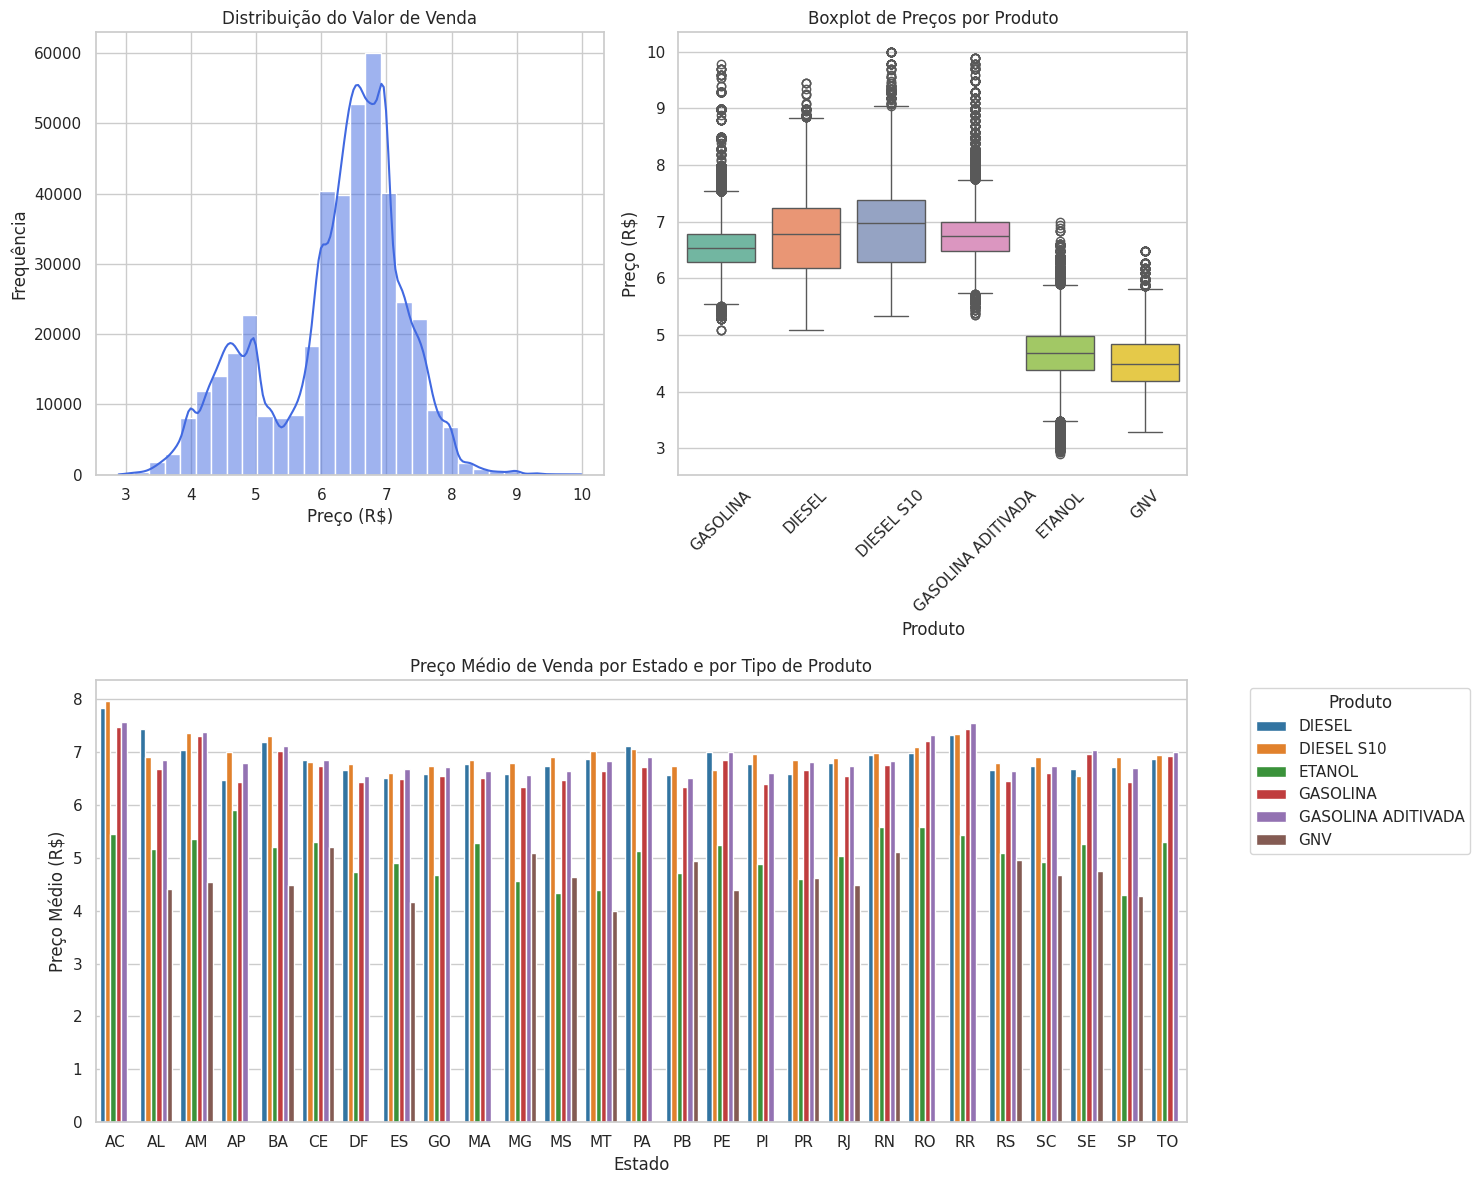

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.figure(figsize=(15, 12))

plt.subplot(2, 2, 1)
sns.histplot(data=df_limpo, x='Valor de Venda', kde=True, bins=30, color='royalblue')
plt.title('Distribuição do Valor de Venda')
plt.xlabel('Preço (R$)')
plt.ylabel('Frequência')

plt.subplot(2, 2, 2)
sns.boxplot(data=df_limpo, x='Produto', y='Valor de Venda', hue='Produto', palette='Set2', legend=False)
plt.xticks(rotation=45)
plt.title('Boxplot de Preços por Produto')
plt.xlabel('Produto')
plt.ylabel('Preço (R$)')

plt.subplot(2, 1, 2)
preco_medio_est_prod = df_limpo.groupby(['Estado - Sigla', 'Produto'])['Valor de Venda'].mean().reset_index()

sns.barplot(
    data=preco_medio_est_prod,
    x='Estado - Sigla',
    y='Valor de Venda',
    hue='Produto',
    palette='tab10'
)
plt.title('Preço Médio de Venda por Estado e por Tipo de Produto')
plt.xlabel('Estado')
plt.ylabel('Preço Médio (R$)')
plt.legend(title='Produto', bbox_to_anchor=(1.05, 1), loc='upper left')

plt.tight_layout()
plt.show()

Link para os Dados

Os dados utilizados nesta análise sobre preços de combustíveis automotivos foram obtidos a partir do portal de Dados Abertos do Governo Federal.

* Fonte: Agência Nacional do Petróleo, Gás Natural e Biocombustíveis (ANP)
* Conjunto de Dados: Série Histórica de Preços de Combustíveis e de GLP
* Link de Acesso: [Dados Abertos ANP - Preços dos Combustíveis](https://dados.gov.br/dados/conjuntos-dados/serie-historica-de-precos-de-combustiveis-e-de-glp)
```